In [1]:
from datasets import load_dataset

dataset = load_dataset(
    "eltorio/ROCOv2-radiology",
    split="train",
    streaming=True
)
sample = next(iter(dataset))

g:\NeuroMed-VLM\.conda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


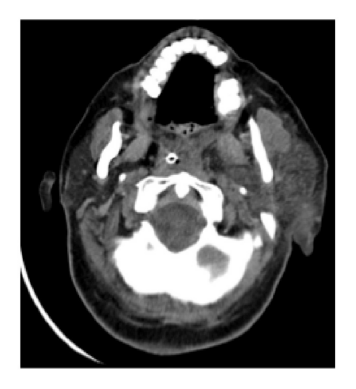

In [2]:
import matplotlib.pyplot as plt

plt.imshow(sample["image"])
plt.axis("off")
plt.show()

In [3]:
print("Image ID:", sample["image_id"])
print("Caption:", sample["caption"])
print("Medical concepts:", sample["cui"])
print("Number of concepts:", len(sample["cui"]))

Image ID: ROCOv2_2023_train_000001
Caption: Head CT demonstrating left parotiditis.
Medical concepts: ['C0040405']
Number of concepts: 1


In [4]:
print(dataset.features)
print(sample.keys())

{'image': Image(mode=None, decode=True), 'image_id': Value('string'), 'caption': Value('string'), 'cui': List(Value('string'))}
dict_keys(['image', 'image_id', 'caption', 'cui'])


In [5]:
iterator = iter(dataset)
for i in range(10):
    sample = next(iterator)
    print(len(sample["caption"].split()),len(sample["cui"]),sample["image"].mode,sample["image"].size)

5 1 RGB (682, 748)
21 1 RGB (307, 224)
13 1 L (358, 263)
14 1 RGB (567, 567)
7 1 RGB (600, 512)
20 1 RGB (800, 511)
13 1 RGB (800, 508)
30 1 RGB (672, 778)
31 1 RGB (672, 837)
7 1 RGB (800, 860)


In [6]:
from itertools import islice

samples = list(islice(dataset, 100))

print("Number of samples:", len(samples))
print("First image ID:", samples[0]["image_id"])
print("Last image ID:", samples[-1]["image_id"])

Number of samples: 100
First image ID: ROCOv2_2023_train_000001
Last image ID: ROCOv2_2023_train_000100


In [8]:
import pandas as pd

records = []
for i in range(len(samples)):
    sample = samples[i]
    records.append({
        "image_id": sample["image_id"],
        "caption_words": len(sample["caption"].split()),
        "cui_count": len(sample["cui"]),
        "width":  sample["image"].size[0],
        "height":  sample["image"].size[1],
        "mode":  sample["image"].mode
    })

df = pd.DataFrame(records)
display(df.head())
print(df.describe())

,image_id,caption_words,cui_count,width,height,mode
0,ROCOv2_2023_train_000001,5,1,682,748,RGB
1,ROCOv2_2023_train_000002,21,1,307,224,RGB
2,ROCOv2_2023_train_000003,13,1,358,263,L
3,ROCOv2_2023_train_000004,14,1,567,567,RGB
4,ROCOv2_2023_train_000005,7,1,600,512,RGB


       caption_words   cui_count        width      height
count     100.000000  100.000000   100.000000   100.00000
mean       19.320000    1.370000   682.730000   617.31000
std        15.574442    0.760847   183.352498   207.19652
min         1.000000    1.000000   307.000000   224.00000
25%         9.000000    1.000000   600.000000   472.00000
50%        16.000000    1.000000   676.500000   614.00000
75%        25.250000    1.000000   767.000000   726.50000
max       105.000000    3.000000  1592.000000  1205.00000


19.32
16.0


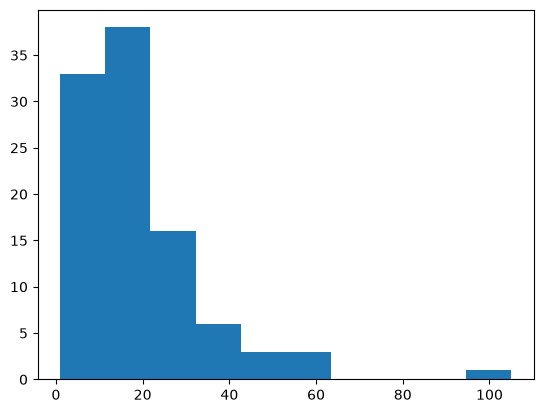

In [ ]:
import matplotlib.pyplot as plt
plt.hist(df["caption_words"])
print(df["caption_words"].mean())
print(df["caption_words"].median())
print(df["caption_words"].quantile([0.50, 0.90, 0.95, 0.99]))

cui_count
1    80
2     3
3    17
Name: count, dtype: int64


<Axes: xlabel='cui_count'>

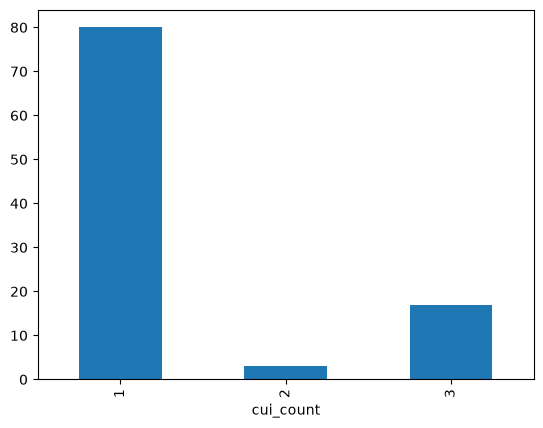

In [17]:
print(df["cui_count"].value_counts().sort_index())
counts = df["cui_count"].value_counts().sort_index()
counts.plot(kind = "bar")

In [19]:
print(df["mode"].value_counts().sort_index())

mode
L      25
RGB    75
Name: count, dtype: int64


0.50     676.5
0.90     800.0
0.95     804.8
0.99    1592.0
Name: width, dtype: float64
             width      height
count   100.000000   100.00000
mean    682.730000   617.31000
std     183.352498   207.19652
min     307.000000   224.00000
25%     600.000000   472.00000
50%     676.500000   614.00000
75%     767.000000   726.50000
max    1592.000000  1205.00000


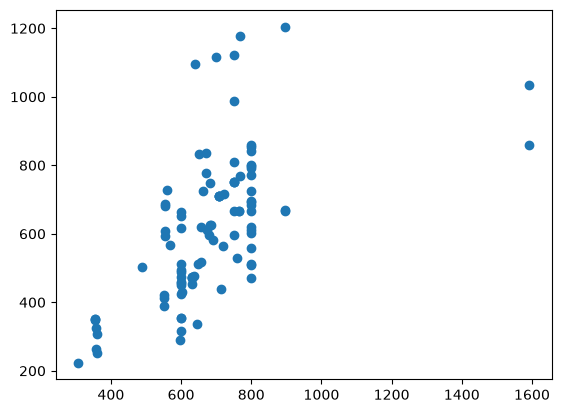

In [22]:
plt.scatter(df["width"], df["height"])
print(df["width"].quantile([0.5,0.9,0.95,0.99]))
print(df[["width", "height"]].describe())

In [2]:
from datasets import load_dataset
from itertools import islice

# 1. 使用streaming方式加载ROCOv2 train split
ds = load_dataset("eltorio/ROCOv2-radiology",split= "train",streaming = True)

# 2. 固定seed并设置5000条shuffle buffer
shuffled_ds = ds.shuffle(seed = 42, buffer_size = 5000)

# 3. 从shuffled_ds中取1000条

samples= list(islice(shuffled_ds, 1000))


print("Number of samples:", len(samples))
print("First 5 IDs:", [x["image_id"] for x in samples[:5]])

g:\NeuroMed-VLM\.conda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Number of samples: 1000
First 5 IDs: ['ROCOv2_2023_train_022322', 'ROCOv2_2023_train_033610', 'ROCOv2_2023_train_024899', 'ROCOv2_2023_train_004777', 'ROCOv2_2023_train_046930']


In [13]:
record = []
for i in range(len(samples)):
    sample = samples[i]
    record.append({
        "image_id": sample["image_id"],
        "image": sample["image"],
        "caption": sample["caption"],
        "cui": sample["cui"],
        "width":  sample["image"].size[0],
        "height":  sample["image"].size[1],
        "mode":  sample["image"].mode
    })
    

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
df =pd.DataFrame(record)
                

In [16]:
from transformers import AutoTokenizer

model_name = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"

tokenizer = AutoTokenizer.from_pretrained(model_name)

In [21]:
caption = df["caption"].iloc[0]

tokens = tokenizer.tokenize(caption)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original:", caption)
print("Words:", len(caption.split()))
print("Tokens:", tokens)
print("Token IDs:", token_ids)
print("Token count:", len(tokens))

Original: Axial section of contrast enhanced CT, with sinogram probe (arrow) within the tract, and no evidence of filling defect or side‐branching of tract.
Words: 23
Tokens: ['axial', 'section', 'of', 'contrast', 'enhanced', 'ct', ',', 'with', 'sin', '##ogram', 'probe', '(', 'arrow', ')', 'within', 'the', 'tract', ',', 'and', 'no', 'evidence', 'of', 'filling', 'defect', 'or', 'side', '‐', 'branching', 'of', 'tract', '.']
Token IDs: [9438, 3314, 1927, 3320, 4256, 3369, 16, 1956, 3132, 7539, 5598, 12, 5583, 13, 2651, 1920, 6482, 16, 1930, 2239, 3095, 1927, 12919, 7374, 2014, 4159, 226, 13898, 1927, 6482, 18]
Token count: 31


In [20]:
encoded = tokenizer(caption)

print("Input IDs:", encoded["input_ids"])
print("Attention Mask:", encoded["attention_mask"])
print("Sequence Length:", len(encoded["input_ids"]))

Input IDs: [2, 9438, 3314, 1927, 3320, 4256, 3369, 16, 1956, 3132, 7539, 5598, 12, 5583, 13, 2651, 1920, 6482, 16, 1930, 2239, 3095, 1927, 12919, 7374, 2014, 4159, 226, 13898, 1927, 6482, 18, 3]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Sequence Length: 33


In [23]:
encoded_list = tokenizer(caption)
encoded_pt = tokenizer(caption, return_tensors="pt")

print(type(encoded_list))
print(type(encoded_list["input_ids"]))

print(type(encoded_pt))
print(type(encoded_pt["input_ids"]))

print(encoded_list["input_ids"])
print(encoded_pt["input_ids"])

<class 'transformers.tokenization_utils_base.BatchEncoding'>
<class 'list'>
<class 'transformers.tokenization_utils_base.BatchEncoding'>
<class 'torch.Tensor'>
[2, 9438, 3314, 1927, 3320, 4256, 3369, 16, 1956, 3132, 7539, 5598, 12, 5583, 13, 2651, 1920, 6482, 16, 1930, 2239, 3095, 1927, 12919, 7374, 2014, 4159, 226, 13898, 1927, 6482, 18, 3]
tensor([[    2,  9438,  3314,  1927,  3320,  4256,  3369,    16,  1956,  3132,
          7539,  5598,    12,  5583,    13,  2651,  1920,  6482,    16,  1930,
          2239,  3095,  1927, 12919,  7374,  2014,  4159,   226, 13898,  1927,
          6482,    18,     3]])


(array([314., 386., 170.,  74.,  30.,  16.,   5.,   3.,   1.,   1.]),
 array([  3. ,  18.6,  34.2,  49.8,  65.4,  81. ,  96.6, 112.2, 127.8,
        143.4, 159. ]),
 <BarContainer object of 10 artists>)

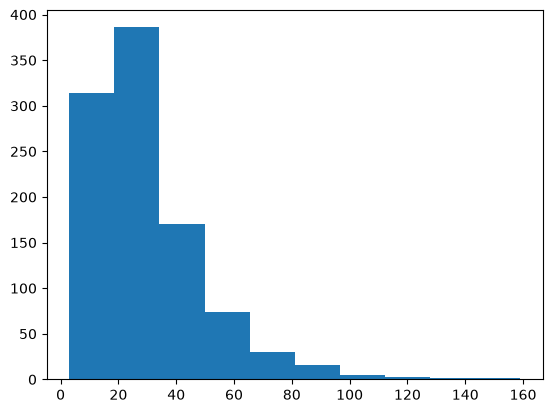

In [25]:
token_num = []
for i in range(len(samples)):
    sample = samples[i]
    caption = sample["caption"]
    token_num.append(len(tokenizer(caption).tokens()))
plt.hist(token_num)

In [29]:
import numpy as np
np.percentile(np.array(token_num),[50,90,95,99])

array([25.5 , 54.  , 68.  , 94.08])

In [31]:
arr = np.array(token_num)

ratio_64 = np.sum(np.array(token_num)>64)
ratio_128 = np.sum(np.array(token_num)>128)
print(ratio_64,ratio_128)

57 2


In [32]:
captions = df["caption"].iloc[:4].tolist()

encoded_batch = tokenizer(
    captions,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print(encoded_batch["input_ids"].shape)
print(encoded_batch["attention_mask"])

torch.Size([4, 43])
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])


In [34]:
mask = encoded_batch["attention_mask"]

lengths = mask.sum(dim=1)

print(lengths)
print(lengths.shape)

tensor([33, 43, 23, 18])
torch.Size([4])


In [35]:
from torch.utils.data import Dataset

class MedicalDataset(Dataset):

    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        # 返回数据集的样本数量
        return len(self.samples)

    def __getitem__(self, idx):
        # 取出第idx条数据
        sample = self.samples[idx]

        return {
            "image": sample["image"],
            "caption": sample["caption"],
            "image_id": sample["image_id"]
        }

In [36]:
dataset = MedicalDataset(samples)

print("Dataset length:", len(dataset))

sample_0 = dataset[0]

print("Keys:", sample_0.keys())
print("Caption:", sample_0["caption"])
print("Image type:", type(sample_0["image"]))

Dataset length: 1000
Keys: dict_keys(['image', 'caption', 'image_id'])
Caption: Axial section of contrast enhanced CT, with sinogram probe (arrow) within the tract, and no evidence of filling defect or side‐branching of tract.
Image type: <class 'PIL.PngImagePlugin.PngImageFile'>
